# Sistem Rekomendasi Anime — K-Means (Content-Based)
Alur: **Load & bersihkan → Encoding → Log transform → Scaling → Pilih k → K-Means → Profil cluster → Fungsi rekomendasi → Simpan untuk web**

> Versi perbaikan dari notebook sebelumnya. Bagian yang diubah ditandai **🔧 PERBAIKAN**.

In [1]:
import html
import difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import MultiLabelBinarizer, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import euclidean_distances

PATH_CSV = '/content/anime.csv'   # ganti sesuai lokasi file

## 1. Load data & pembersihan awal
🔧 **PERBAIKAN:**
- Judul seperti `Gintama&#039;` berisi kode HTML → diubah jadi `Gintama'` dengan `html.unescape`, supaya bisa dicari pengguna.
- Anime dewasa (genre *Hentai*) dihapus.
- `reset_index` supaya index rapi setelah baris dihapus (penting agar `df` dan `X` sejajar).

In [2]:
df = pd.read_csv(PATH_CSV)
print('Awal       :', df.shape)

df['name'] = df['name'].apply(html.unescape)
df = df[~df['genre'].str.contains('Hentai', na=False)].reset_index(drop=True)
print('Tanpa Hentai:', df.shape)

df.isnull().sum()

Awal       : (12294, 7)
Tanpa Hentai: (11153, 7)


anime_id      0
name          0
genre        62
type         25
episodes      0
rating      222
members       0
dtype: int64

## 2. Penanganan data kosong
🔧 **PERBAIKAN:** `episodes` diisi **median per type** (TV, Movie, OVA punya jumlah episode yang sangat berbeda), bukan median global.

In [3]:
df['genre']  = df['genre'].fillna('Unknown')
df['type']   = df['type'].fillna('Unknown')
df['rating'] = df['rating'].fillna(df['rating'].median())

df['episodes'] = pd.to_numeric(df['episodes'], errors='coerce')   # 'Unknown' -> NaN
df['episodes'] = df['episodes'].fillna(df.groupby('type')['episodes'].transform('median'))
df['episodes'] = df['episodes'].fillna(df['episodes'].median())   # cadangan jika masih ada NaN

df.isnull().sum()

anime_id    0
name        0
genre       0
type        0
episodes    0
rating      0
members     0
dtype: int64

## 3. Encoding: genre (multi-label) & type (one-hot)

In [4]:
genre_list = df['genre'].apply(lambda x: [g.strip() for g in x.split(',')])
mlb = MultiLabelBinarizer()
df_genre = pd.DataFrame(mlb.fit_transform(genre_list), columns=mlb.classes_)

df_type = pd.get_dummies(df['type'], prefix='type', dtype=int)

print('Jumlah kolom genre:', df_genre.shape[1])
print('Jumlah kolom type :', df_type.shape[1])

Jumlah kolom genre: 43
Jumlah kolom type : 7


## 4. Log transform kolom numerik yang timpang

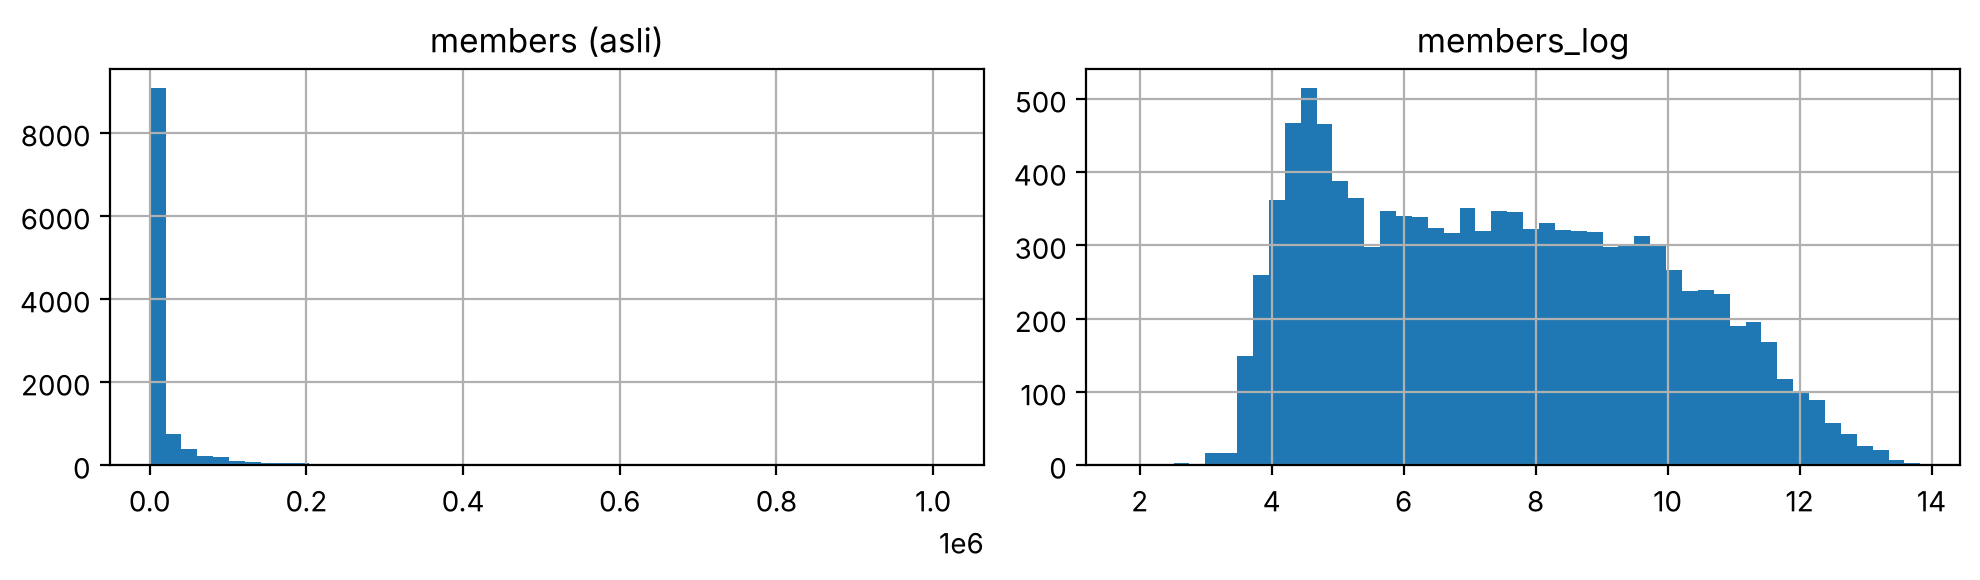

In [5]:
df_num = pd.DataFrame({
    'rating'      : df['rating'],
    'members_log' : np.log1p(df['members']),
    'episodes_log': np.log1p(df['episodes']),
})

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
df['members'].hist(bins=50, ax=ax[0]);  ax[0].set_title('members (asli)')
df_num['members_log'].hist(bins=50, ax=ax[1]); ax[1].set_title('members_log')
plt.tight_layout(); plt.show()

## 5. Susun matriks fitur `X` & scaling
`X` = **semua fitur angka** yang masuk ke K-Means (genre + type + numerik).
🔧 **PERBAIKAN:** Scaler hanya dipasang pada 3 kolom numerik (kolom one-hot sudah 0–1), dan `X` dipisah dari `df` supaya kolom `cluster` tidak ikut tercampur ke fitur.

In [6]:
X = pd.concat([df_genre, df_type, df_num], axis=1)

num_cols = ['rating', 'members_log', 'episodes_log']
scaler = MinMaxScaler()
X[num_cols] = scaler.fit_transform(X[num_cols])

print('Ukuran X:', X.shape)
print('Ada NaN?', X.isna().sum().sum())
X.head()

Ukuran X: (11153, 53)
Ada NaN? 0


,Action,Adventure,Cars,Comedy,Dementia,Demons,Drama,Ecchi,Fantasy,Game,...,type_Movie,type_Music,type_ONA,type_OVA,type_Special,type_TV,type_Unknown,rating,members_log,episodes_log
0,0,0,0,0,0,0,1,0,0,0,...,1,0,0,0,0,0,0,0.924370,0.865412,0.000000
1,1,1,0,0,0,0,1,0,1,0,...,0,0,0,0,0,1,0,0.911164,0.979654,0.510978
2,1,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0.909964,0.818645,0.478225
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0.900360,0.966025,0.370728
4,1,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0.899160,0.841951,0.478225


## 6. Menentukan jumlah cluster (k)
🔧 **PERBAIKAN:** sebelumnya k=5 dipilih tanpa dasar. Di sini dicek dengan **Elbow** (inertia) dan **Silhouette**.

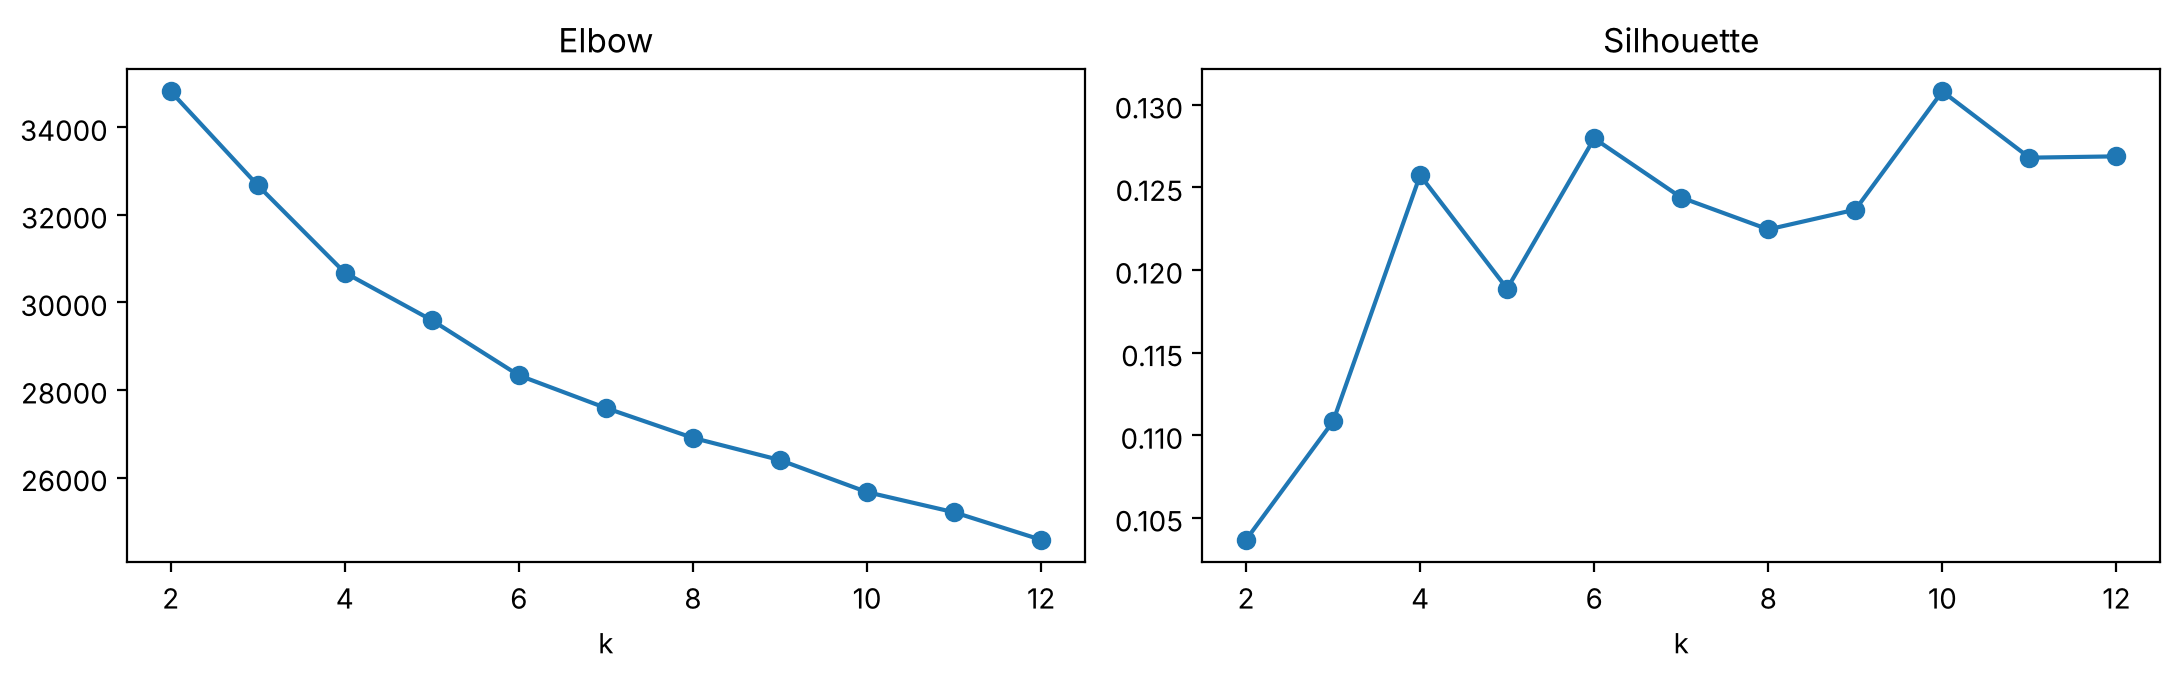

k= 2  silhouette=0.104
k= 3  silhouette=0.111
k= 4  silhouette=0.126
k= 5  silhouette=0.119
k= 6  silhouette=0.128
k= 7  silhouette=0.124
k= 8  silhouette=0.122
k= 9  silhouette=0.124
k=10  silhouette=0.131
k=11  silhouette=0.127
k=12  silhouette=0.127


In [7]:
K = range(2, 13)
inertia, sil = [], []
for k in K:
    m = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertia.append(m.inertia_)
    sil.append(silhouette_score(X, m.labels_, sample_size=4000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(K, inertia, 'o-'); ax[0].set_title('Elbow'); ax[0].set_xlabel('k')
ax[1].plot(K, sil, 'o-');     ax[1].set_title('Silhouette'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.show()

for k, s in zip(K, sil):
    print(f'k={k:2d}  silhouette={s:.3f}')

**Interpretasi:** kurva elbow turun landai (tidak ada siku tajam) dan silhouette rendah (±0,1–0,13). Ini **wajar** untuk data one-hot berdimensi tinggi.
Silhouette tertinggi ada di sekitar **k=10**, dan untuk rekomendasi cluster yang lebih kecil membuat kandidat lebih spesifik → dipakai **k=10**. Silakan coba nilai lain dan bandingkan hasil rekomendasinya.

In [8]:
N_CLUSTERS = 10
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X)     # label disimpan di df, BUKAN di X

print('Silhouette:', round(silhouette_score(X, df['cluster'], sample_size=4000, random_state=42), 3))
df['cluster'].value_counts().sort_index()

Silhouette: 0.131


cluster
0    1544
1     488
2    1102
3     901
4    1112
5     737
6     717
7    1836
8    2079
9     637
Name: count, dtype: int64

## 7. Profil tiap cluster

In [9]:
profil = X.groupby(df['cluster']).mean()
genre_cols = list(mlb.classes_)
type_cols  = list(df_type.columns)

for c in profil.index:
    g = profil.loc[c, genre_cols].sort_values(ascending=False).head(4)
    t = profil.loc[c, type_cols].idxmax().replace('type_', '')
    contoh = df[df['cluster'] == c].sort_values('members', ascending=False)['name'].head(4).tolist()
    print(f"Cluster {c} ({(df['cluster']==c).sum()} anime) | type dominan: {t}")
    print('   genre :', ', '.join(f'{k} ({v:.0%})' for k, v in g.items()))
    print('   contoh:', contoh, '\n')

Cluster 0 (1544 anime) | type dominan: TV
   genre : Comedy (100%), Slice of Life (24%), Romance (23%), School (23%)
   contoh: ['Toradora!', 'No Game No Life', 'Clannad', 'Suzumiya Haruhi no Yuuutsu'] 

Cluster 1 (488 anime) | type dominan: Music
   genre : Music (100%), Kids (20%), Fantasy (8%), Sci-Fi (5%)
   contoh: ['Shelter', 'Black★Rock Shooter', 'Interstella5555: The 5tory of The 5ecret 5tar 5ystem', 'Tengen Toppa Gurren Lagann: Parallel Works'] 

Cluster 2 (1102 anime) | type dominan: TV
   genre : Action (94%), Sci-Fi (42%), Adventure (38%), Shounen (36%)
   contoh: ['Shingeki no Kyojin', 'Sword Art Online', 'Fullmetal Alchemist: Brotherhood', 'Angel Beats!'] 

Cluster 3 (901 anime) | type dominan: Special
   genre : Comedy (100%), Shounen (20%), Action (17%), Adventure (17%)
   contoh: ['Angel Beats! Specials', 'Kokoro Connect: Michi Random', 'Durarara!! Specials', 'Baccano! Specials'] 

Cluster 4 (1112 anime) | type dominan: TV
   genre : Drama (28%), Adventure (27%), Fanta

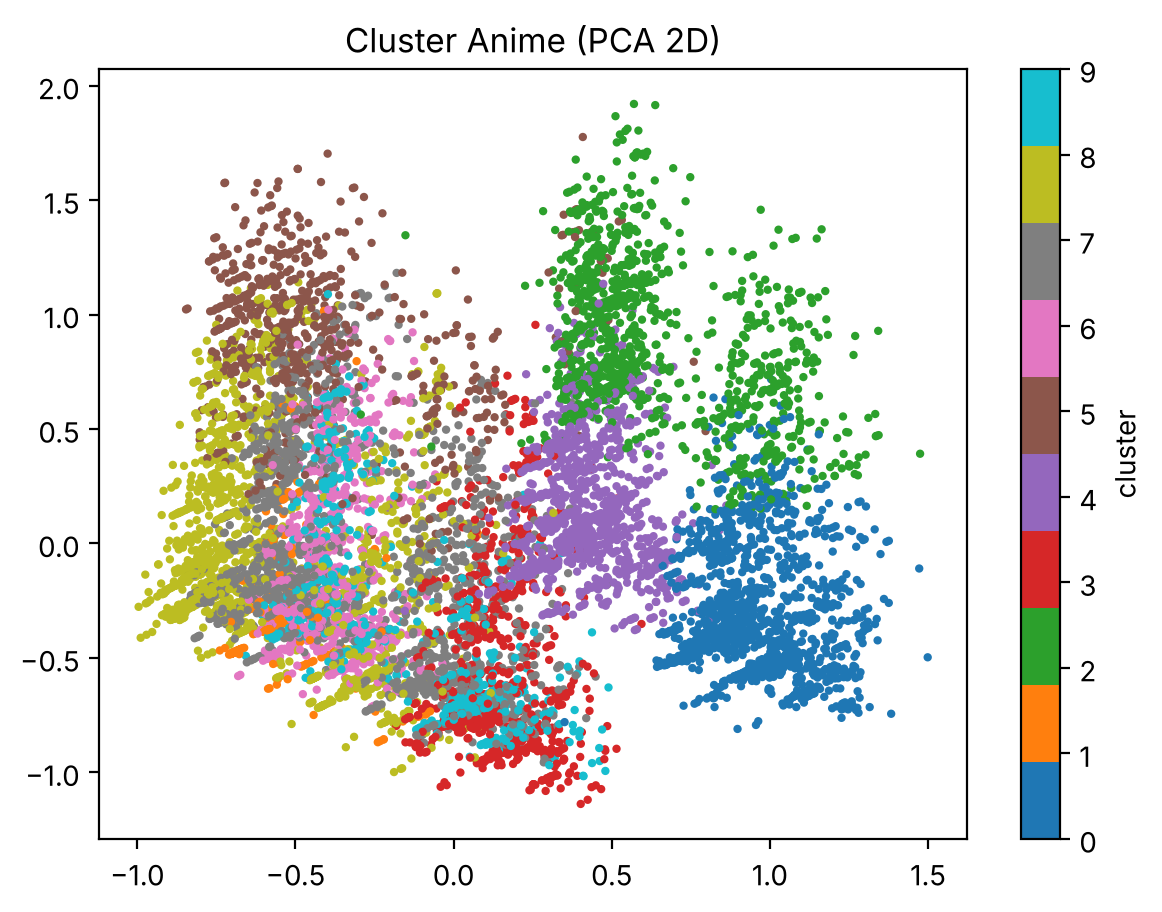

In [10]:
X2 = PCA(n_components=2, random_state=42).fit_transform(X)
plt.figure(figsize=(7, 5))
plt.scatter(X2[:, 0], X2[:, 1], c=df['cluster'], cmap='tab10', s=4)
plt.colorbar(label='cluster'); plt.title('Cluster Anime (PCA 2D)')
plt.show()

## 8. Fungsi rekomendasi
1. Cari anime dari judul input → 2. ambil cluster-nya → 3. hitung jarak ke anggota cluster yang sama → 4. tampilkan **k terdekat**.

In [11]:
def cari_judul(kata):
    """Bantu mencari judul yang tepat (pencarian sebagian)."""
    hasil = df[df['name'].str.contains(kata, case=False, regex=False)]
    if hasil.empty:   # tidak ada yang persis -> cari yang mirip (toleran salah ketik)
        mirip = difflib.get_close_matches(kata.lower(), df['name'].str.lower().tolist(), n=10, cutoff=0.6)
        hasil = df[df['name'].str.lower().isin(mirip)]
    return hasil[['name', 'type', 'members']].sort_values('members', ascending=False).head(10)


def rekomendasi(judul, k=10):
    cocok = df[df['name'].str.lower() == judul.lower()]
    if cocok.empty:
        print(f"'{judul}' tidak ditemukan. Mungkin maksudnya:")
        return cari_judul(judul)

    idx = cocok.index[0]
    c = df.loc[idx, 'cluster']
    anggota = df[(df['cluster'] == c) & (df.index != idx)].index

    jarak = euclidean_distances(X.loc[[idx]], X.loc[anggota])[0]
    urut = np.argsort(jarak)[:k]

    hasil = df.loc[anggota[urut], ['name', 'genre', 'type', 'episodes', 'rating']].copy()
    hasil['jarak'] = jarak[urut].round(3)
    print(f"Input: {df.loc[idx, 'name']} | cluster {c} | {df.loc[idx, 'genre']}")
    return hasil.reset_index(drop=True)

In [12]:
rekomendasi('Naruto', k=10)

Input: Naruto | cluster 2 | Action, Comedy, Martial Arts, Shounen, Super Power


,name,genre,type,episodes,rating,jarak
0,Naruto: Shippuuden,"Action, Comedy, Martial Arts, Shounen, Super P...",TV,24.0,7.94,0.321
1,Katekyo Hitman Reborn!,"Action, Comedy, Shounen, Super Power",TV,203.0,8.37,1.006
2,Bleach,"Action, Comedy, Shounen, Super Power, Supernat...",TV,366.0,7.95,1.416
3,Dragon Ball Z,"Action, Adventure, Comedy, Fantasy, Martial Ar...",TV,291.0,8.32,1.417
4,Dragon Ball Kai,"Action, Adventure, Comedy, Fantasy, Martial Ar...",TV,97.0,7.95,1.427
5,Shijou Saikyou no Deshi Kenichi,"Action, Comedy, Martial Arts, School, Shounen",TV,50.0,8.25,1.438
6,Dragon Ball Kai (2014),"Action, Adventure, Comedy, Fantasy, Martial Ar...",TV,61.0,8.01,1.445
7,Rekka no Honoo,"Action, Adventure, Martial Arts, Shounen, Supe...",TV,42.0,7.44,1.456
8,Dragon Ball Super,"Action, Adventure, Comedy, Fantasy, Martial Ar...",TV,24.0,7.40,1.459
9,Tenjou Tenge,"Action, Comedy, Ecchi, Martial Arts, School, S...",TV,24.0,7.10,1.461


In [13]:
rekomendasi('Kimi no Na wa.', k=10)

Input: Kimi no Na wa. | cluster 8 | Drama, Romance, School, Supernatural


,name,genre,type,episodes,rating,jarak
0,Kokoro ga Sakebitagatterunda.,"Drama, Romance, School",Movie,1.0,8.32,1.013
1,Air Movie,"Drama, Romance, Supernatural",Movie,1.0,7.39,1.036
2,Aura: Maryuuin Kouga Saigo no Tatakai,"Comedy, Drama, Romance, School, Supernatural",Movie,1.0,7.67,1.037
3,Harmonie,"Drama, School, Supernatural",Movie,1.0,7.52,1.037
4,Hotarubi no Mori e,"Drama, Romance, Shoujo, Supernatural",Movie,1.0,8.61,1.417
5,Momo e no Tegami,"Drama, Supernatural",Movie,1.0,7.78,1.436
6,"""Bungaku Shoujo"" Movie","Drama, Mystery, Romance, School",Movie,1.0,7.63,1.436
7,Clannad Movie,"Drama, Fantasy, Romance, School",Movie,1.0,7.35,1.436
8,Zutto Mae kara Suki deshita.: Kokuhaku Jikkou ...,"Romance, School",Movie,1.0,7.47,1.440
9,Suki ni Naru Sono Shunkan wo.: Kokuhaku Jikkou...,"Comedy, Drama, Romance, School",Movie,1.0,6.62,1.473


In [14]:
rekomendasi('Death Note', k=10)

Input: Death Note | cluster 4 | Mystery, Police, Psychological, Supernatural, Thriller


,name,genre,type,episodes,rating,jarak
0,Higurashi no Naku Koro ni Kai,"Mystery, Psychological, Supernatural, Thriller",TV,24.0,8.41,1.011
1,Mousou Dairinin,"Drama, Mystery, Police, Psychological, Superna...",TV,13.0,7.74,1.031
2,Higurashi no Naku Koro ni,"Horror, Mystery, Psychological, Supernatural, ...",TV,26.0,8.17,1.419
3,Jigoku Shoujo Mitsuganae,"Mystery, Psychological, Supernatural",TV,26.0,7.81,1.439
4,Yakushiji Ryouko no Kaiki Jikenbo,"Mystery, Police, Supernatural",TV,13.0,7.19,1.482
5,Saint Luminous Jogakuin,"Mystery, Psychological, Supernatural",TV,13.0,6.17,1.548
6,Shiki,"Mystery, Supernatural, Thriller, Vampire",TV,22.0,7.99,1.740
7,Boku dake ga Inai Machi,"Mystery, Psychological, Seinen, Supernatural",TV,12.0,8.65,1.741
8,Jigoku Shoujo,"Horror, Mystery, Psychological, Supernatural",TV,26.0,7.79,1.743
9,Zankyou no Terror,"Psychological, Thriller",TV,11.0,8.26,1.743


In [15]:
rekomendasi('naruto shippuden')   # contoh judul tidak persis -> muncul saran

'naruto shippuden' tidak ditemukan. Mungkin maksudnya:


,name,type,members
615,Naruto: Shippuuden,TV,533578
1827,Naruto: Shippuuden Movie 1,Movie,108170
1828,Naruto: Shippuuden Movie 2 - Kizuna,Movie,97818
2458,Naruto Shippuuden: Sunny Side Battle,Special,13014
7439,Toushinden,OVA,2400
8982,Iruka to Shounen,TV,118
8750,Hana to Shounen,OVA,55


## 9. Simpan untuk web
Web cukup memuat `anime_clustered.csv` + `anime_features.csv` lalu memakai fungsi `rekomendasi()` yang sama.

In [16]:
df.to_csv('anime_clustered.csv', index=False)
X.to_csv('anime_features.csv', index=False)
joblib.dump(kmeans, 'kmeans.pkl')
joblib.dump(scaler, 'scaler.pkl')
print('Tersimpan: anime_clustered.csv, anime_features.csv, kmeans.pkl, scaler.pkl')

Tersimpan: anime_clustered.csv, anime_features.csv, kmeans.pkl, scaler.pkl
